In [121]:
import scanpy as sc
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

In [62]:
adata = sc.datasets.pbmc3k()  # Load the PBMC 3k dataset

In [63]:
print(adata.X)

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 2286884 stored elements and shape (2700, 32738)>
  Coords	Values
  (0, 70)	1.0
  (0, 166)	1.0
  (0, 178)	2.0
  (0, 326)	1.0
  (0, 363)	1.0
  (0, 410)	1.0
  (0, 412)	1.0
  (0, 492)	41.0
  (0, 494)	1.0
  (0, 495)	1.0
  (0, 496)	1.0
  (0, 525)	1.0
  (0, 556)	2.0
  (0, 558)	6.0
  (0, 671)	1.0
  (0, 684)	1.0
  (0, 735)	1.0
  (0, 770)	1.0
  (0, 793)	1.0
  (0, 820)	1.0
  (0, 859)	2.0
  (0, 871)	1.0
  (0, 908)	15.0
  (0, 926)	1.0
  (0, 941)	1.0
  :	:
  (2699, 31849)	1.0
  (2699, 31855)	1.0
  (2699, 31887)	1.0
  (2699, 31949)	2.0
  (2699, 31970)	2.0
  (2699, 32022)	17.0
  (2699, 32044)	1.0
  (2699, 32047)	2.0
  (2699, 32059)	1.0
  (2699, 32065)	1.0
  (2699, 32066)	1.0
  (2699, 32082)	1.0
  (2699, 32186)	1.0
  (2699, 32193)	1.0
  (2699, 32322)	1.0
  (2699, 32442)	1.0
  (2699, 32543)	1.0
  (2699, 32581)	1.0
  (2699, 32641)	1.0
  (2699, 32696)	3.0
  (2699, 32697)	1.0
  (2699, 32698)	7.0
  (2699, 32702)	1.0
  (2699, 32705)	1.0
  (2699, 3

In [64]:
print(adata)
print(adata.shape)
print(adata.obs.head())
print(adata.var.head())

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
(2700, 32738)
Empty DataFrame
Columns: []
Index: [AAACATACAACCAC-1, AAACATTGAGCTAC-1, AAACATTGATCAGC-1, AAACCGTGCTTCCG-1, AAACCGTGTATGCG-1]
                     gene_ids
index                        
MIR1302-10    ENSG00000243485
FAM138A       ENSG00000237613
OR4F5         ENSG00000186092
RP11-34P13.7  ENSG00000238009
RP11-34P13.8  ENSG00000239945


In [65]:
print(adata.obs.head())

Empty DataFrame
Columns: []
Index: [AAACATACAACCAC-1, AAACATTGAGCTAC-1, AAACATTGATCAGC-1, AAACCGTGCTTCCG-1, AAACCGTGTATGCG-1]


In [66]:
full_matrix = pd.DataFrame(
    adata.X.toarray(),
    index=adata.obs_names,
    columns=adata.var_names
)

In [67]:
full_matrix 

index,MIR1302-10,FAM138A,OR4F5,RP11-34P13.7,RP11-34P13.8,AL627309.1,RP11-34P13.14,RP11-34P13.9,AP006222.2,RP4-669L17.10,...,KIR3DL2-1,AL590523.1,CT476828.1,PNRC2-1,SRSF10-1,AC145205.1,BAGE5,CU459201.1,AC002321.2,AC002321.1
index,,,,,,,,,,,,,,,,,,,,,
AAACATACAACCAC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAACATTGAGCTAC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAACATTGATCAGC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAACCGTGCTTCCG-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAACCGTGTATGCG-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTCGAACTCTCAT-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
TTTCTACTGAGGCA-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
TTTCTACTTCCTCG-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# Quality Control

In [68]:
# 1. Mark mitochondrial genes
adata.var["mt"] = adata.var_names.str.startswith("MT-")

# 2. Compute QC metrics
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],
    percent_top=None,
    log1p=False,
    inplace=True
)

# Inspect the new QC columns
print(
    adata.obs[
        ["n_genes_by_counts", "total_counts", "pct_counts_mt"]
    ].head()
)

                  n_genes_by_counts  total_counts  pct_counts_mt
index                                                           
AAACATACAACCAC-1                781        2421.0       3.015283
AAACATTGAGCTAC-1               1352        4903.0       3.793596
AAACATTGATCAGC-1               1131        3149.0       0.889171
AAACCGTGCTTCCG-1                960        2639.0       1.743085
AAACCGTGTATGCG-1                522         981.0       1.223242


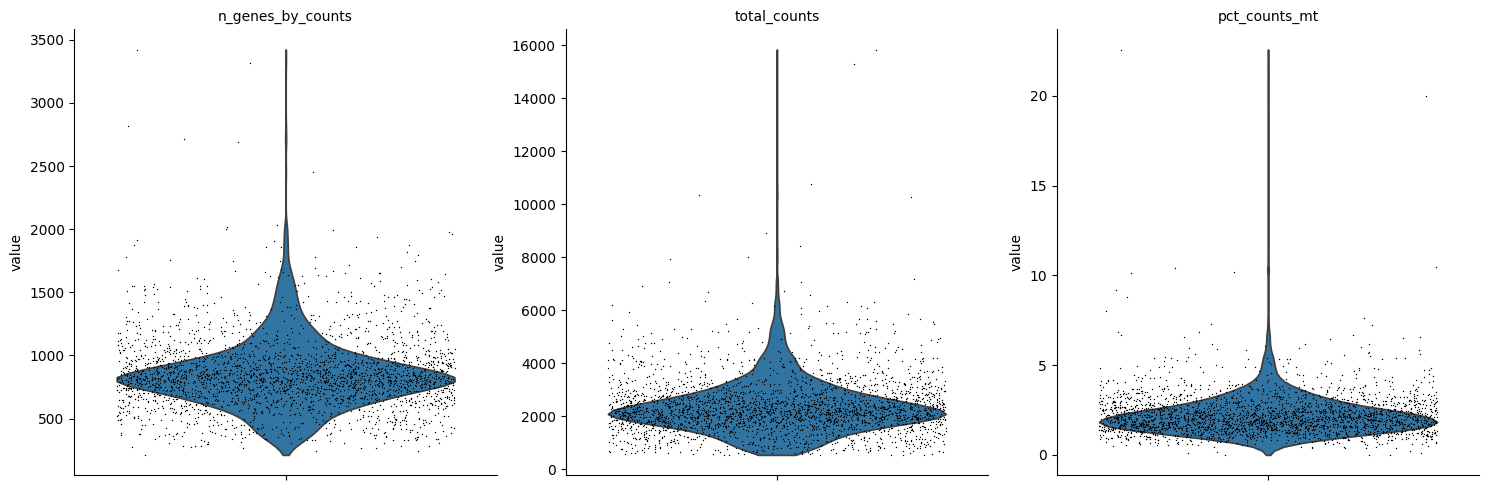

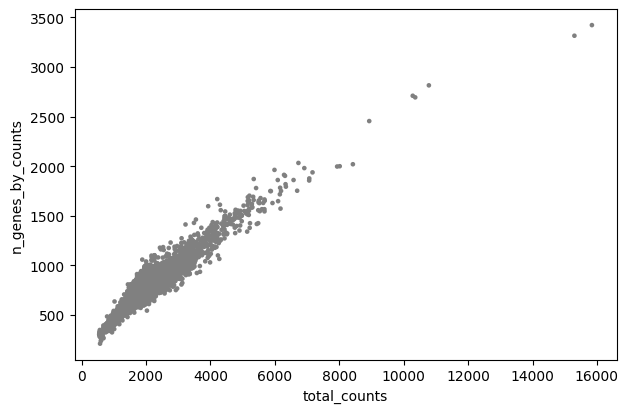

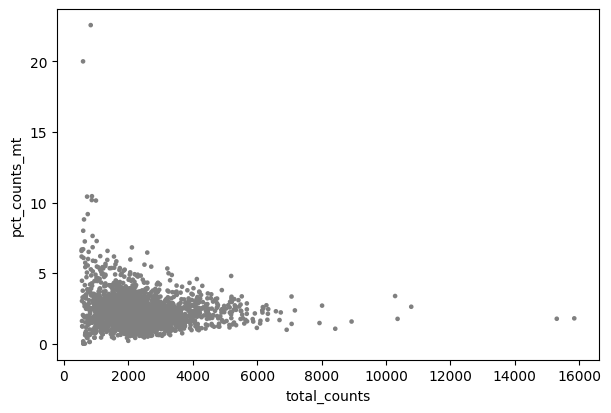

In [69]:
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True
)

sc.pl.scatter(
    adata,
    x="total_counts",
    y="n_genes_by_counts"
)

sc.pl.scatter(
    adata,
    x="total_counts",
    y="pct_counts_mt"
)

In [70]:
# Remove cells with fewer than 200 detected genes
sc.pp.filter_cells(adata, min_genes=200)

# Remove genes detected in fewer than 3 cells
sc.pp.filter_genes(adata, min_cells=3)

# Remove cells with very high gene counts
adata = adata[adata.obs["n_genes_by_counts"] < 2500, :].copy()

# Remove cells with high mitochondrial percentage
adata = adata[adata.obs["pct_counts_mt"] < 5, :].copy()

In [71]:
print(adata.shape)

(2638, 13714)


In [72]:
matrix = pd.DataFrame(
    adata.X.toarray(),
    index=adata.obs_names,
    columns=adata.var_names
)

In [73]:
matrix

index,AL627309.1,AP006222.2,RP11-206L10.2,RP11-206L10.9,LINC00115,NOC2L,KLHL17,PLEKHN1,RP11-54O7.17,HES4,...,MT-ND4L,MT-ND4,MT-ND5,MT-ND6,MT-CYB,AC145212.1,AL592183.1,AL354822.1,PNRC2-1,SRSF10-1
index,,,,,,,,,,,,,,,,,,,,,
AAACATACAACCAC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,10.0,1.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0
AAACATTGAGCTAC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,33.0,1.0,0.0,8.0,0.0,1.0,0.0,0.0,0.0
AAACATTGATCAGC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,3.0,2.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0
AAACCGTGCTTCCG-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,3.0,2.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0
AAACCGTGTATGCG-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTCGAACTCTCAT-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
TTTCTACTGAGGCA-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,2.0,1.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0
TTTCTACTTCCTCG-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,7.0,0.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0


# Normalization + log1p

In [74]:
# Normalize each cell to the same total count
sc.pp.normalize_total(
    adata,
    target_sum=1e4
)

# Log-transform the normalized counts
sc.pp.log1p(adata)

In [75]:
norm_matrix = pd.DataFrame(
    adata.X.toarray(),
    index=adata.obs_names,
    columns=adata.var_names
)

In [76]:
adata.layers["counts"] = adata.X.copy()

# Highly Variable Genes

In [77]:
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor="seurat"
)

In [78]:
print(adata.var["highly_variable"].value_counts())

highly_variable
False    11714
True      2000
Name: count, dtype: int64


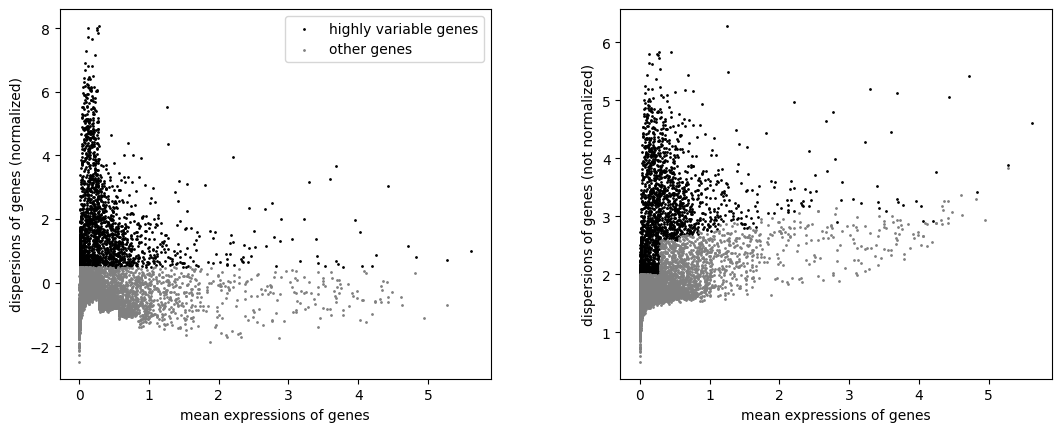

In [79]:
sc.pl.highly_variable_genes(adata)

In [90]:
adata_hgv = adata[:, adata.var["highly_variable"]].copy()

# Cell-type Labeling

In [91]:
# PCA
sc.tl.pca(adata_hgv)

# Build nearest-neighbor graph
sc.pp.neighbors(adata_hgv)

# UMAP
sc.tl.umap(adata_hgv)

# Cluster cells
sc.tl.leiden(adata_hgv, resolution=0.5)

In [92]:
adata.obsm["X_umap"] = adata_hgv.obsm["X_umap"].copy()
adata.obs["leiden"] = adata_hgv.obs["leiden"].copy()

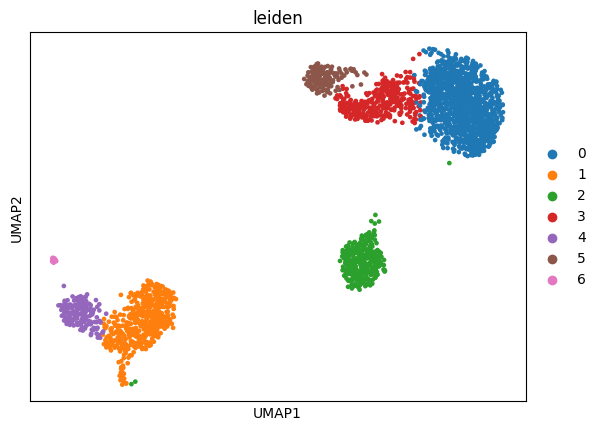

In [93]:
sc.pl.umap(adata, color="leiden")

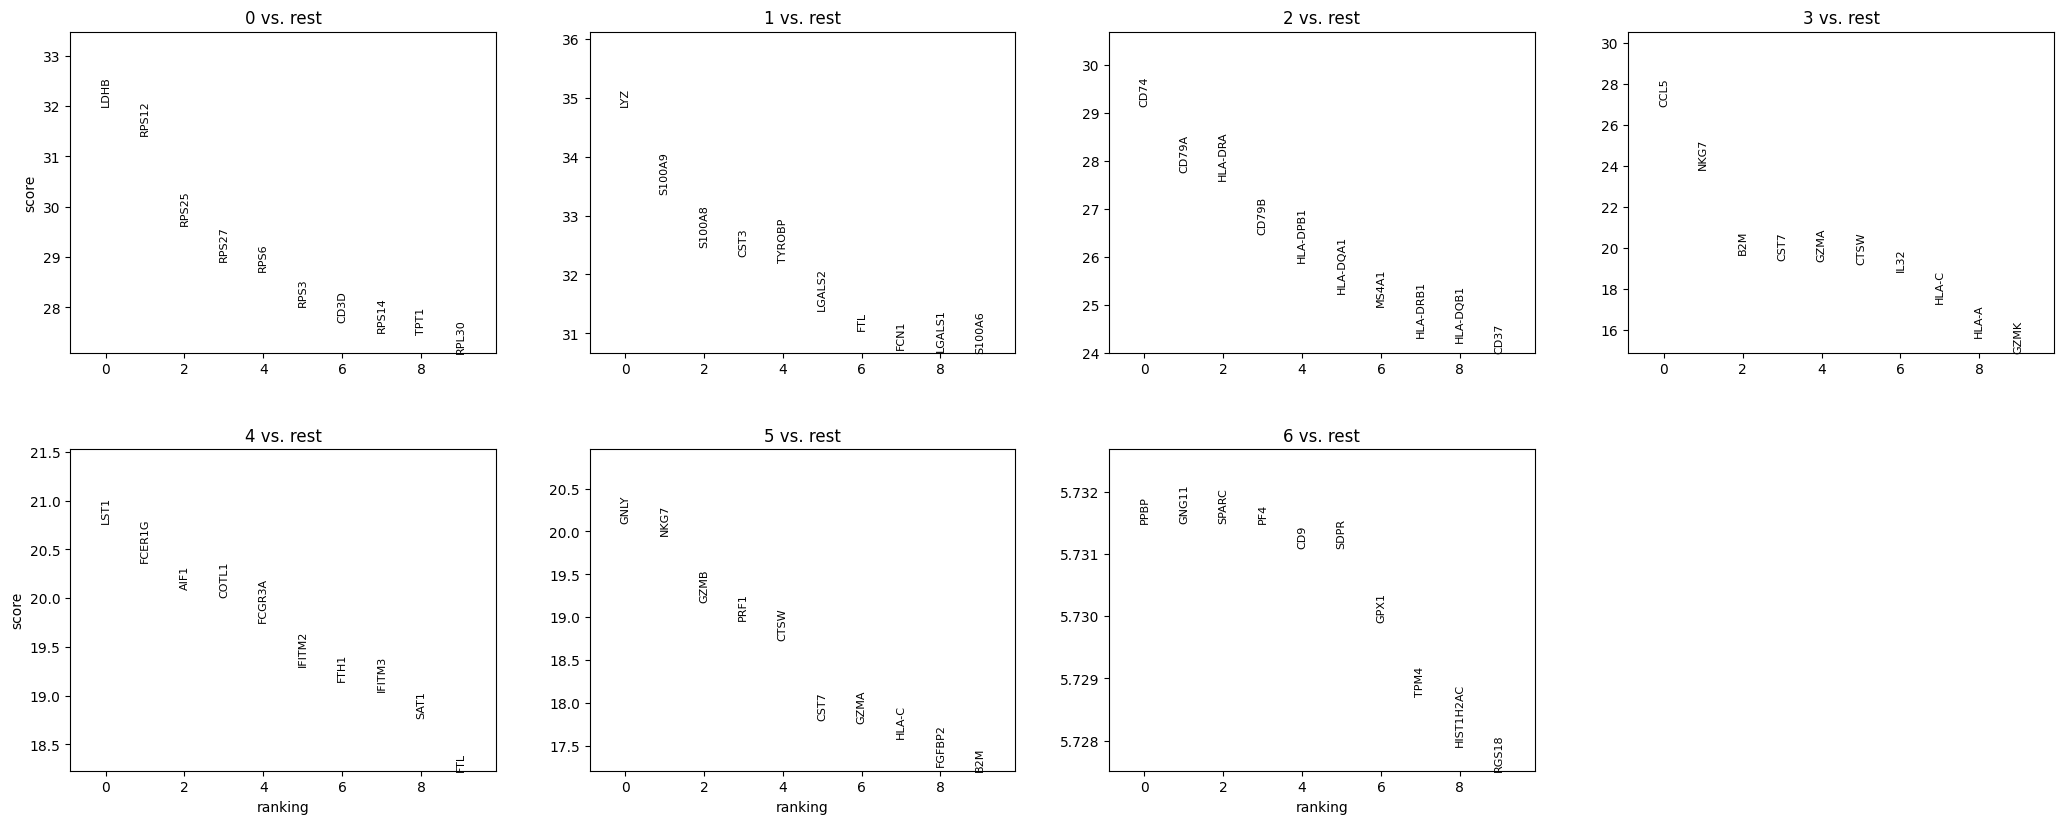

In [94]:
sc.tl.rank_genes_groups(
    adata,
    groupby="leiden",
    method="wilcoxon"
)

sc.pl.rank_genes_groups(
    adata,
    n_genes=10,
    sharey=False
)

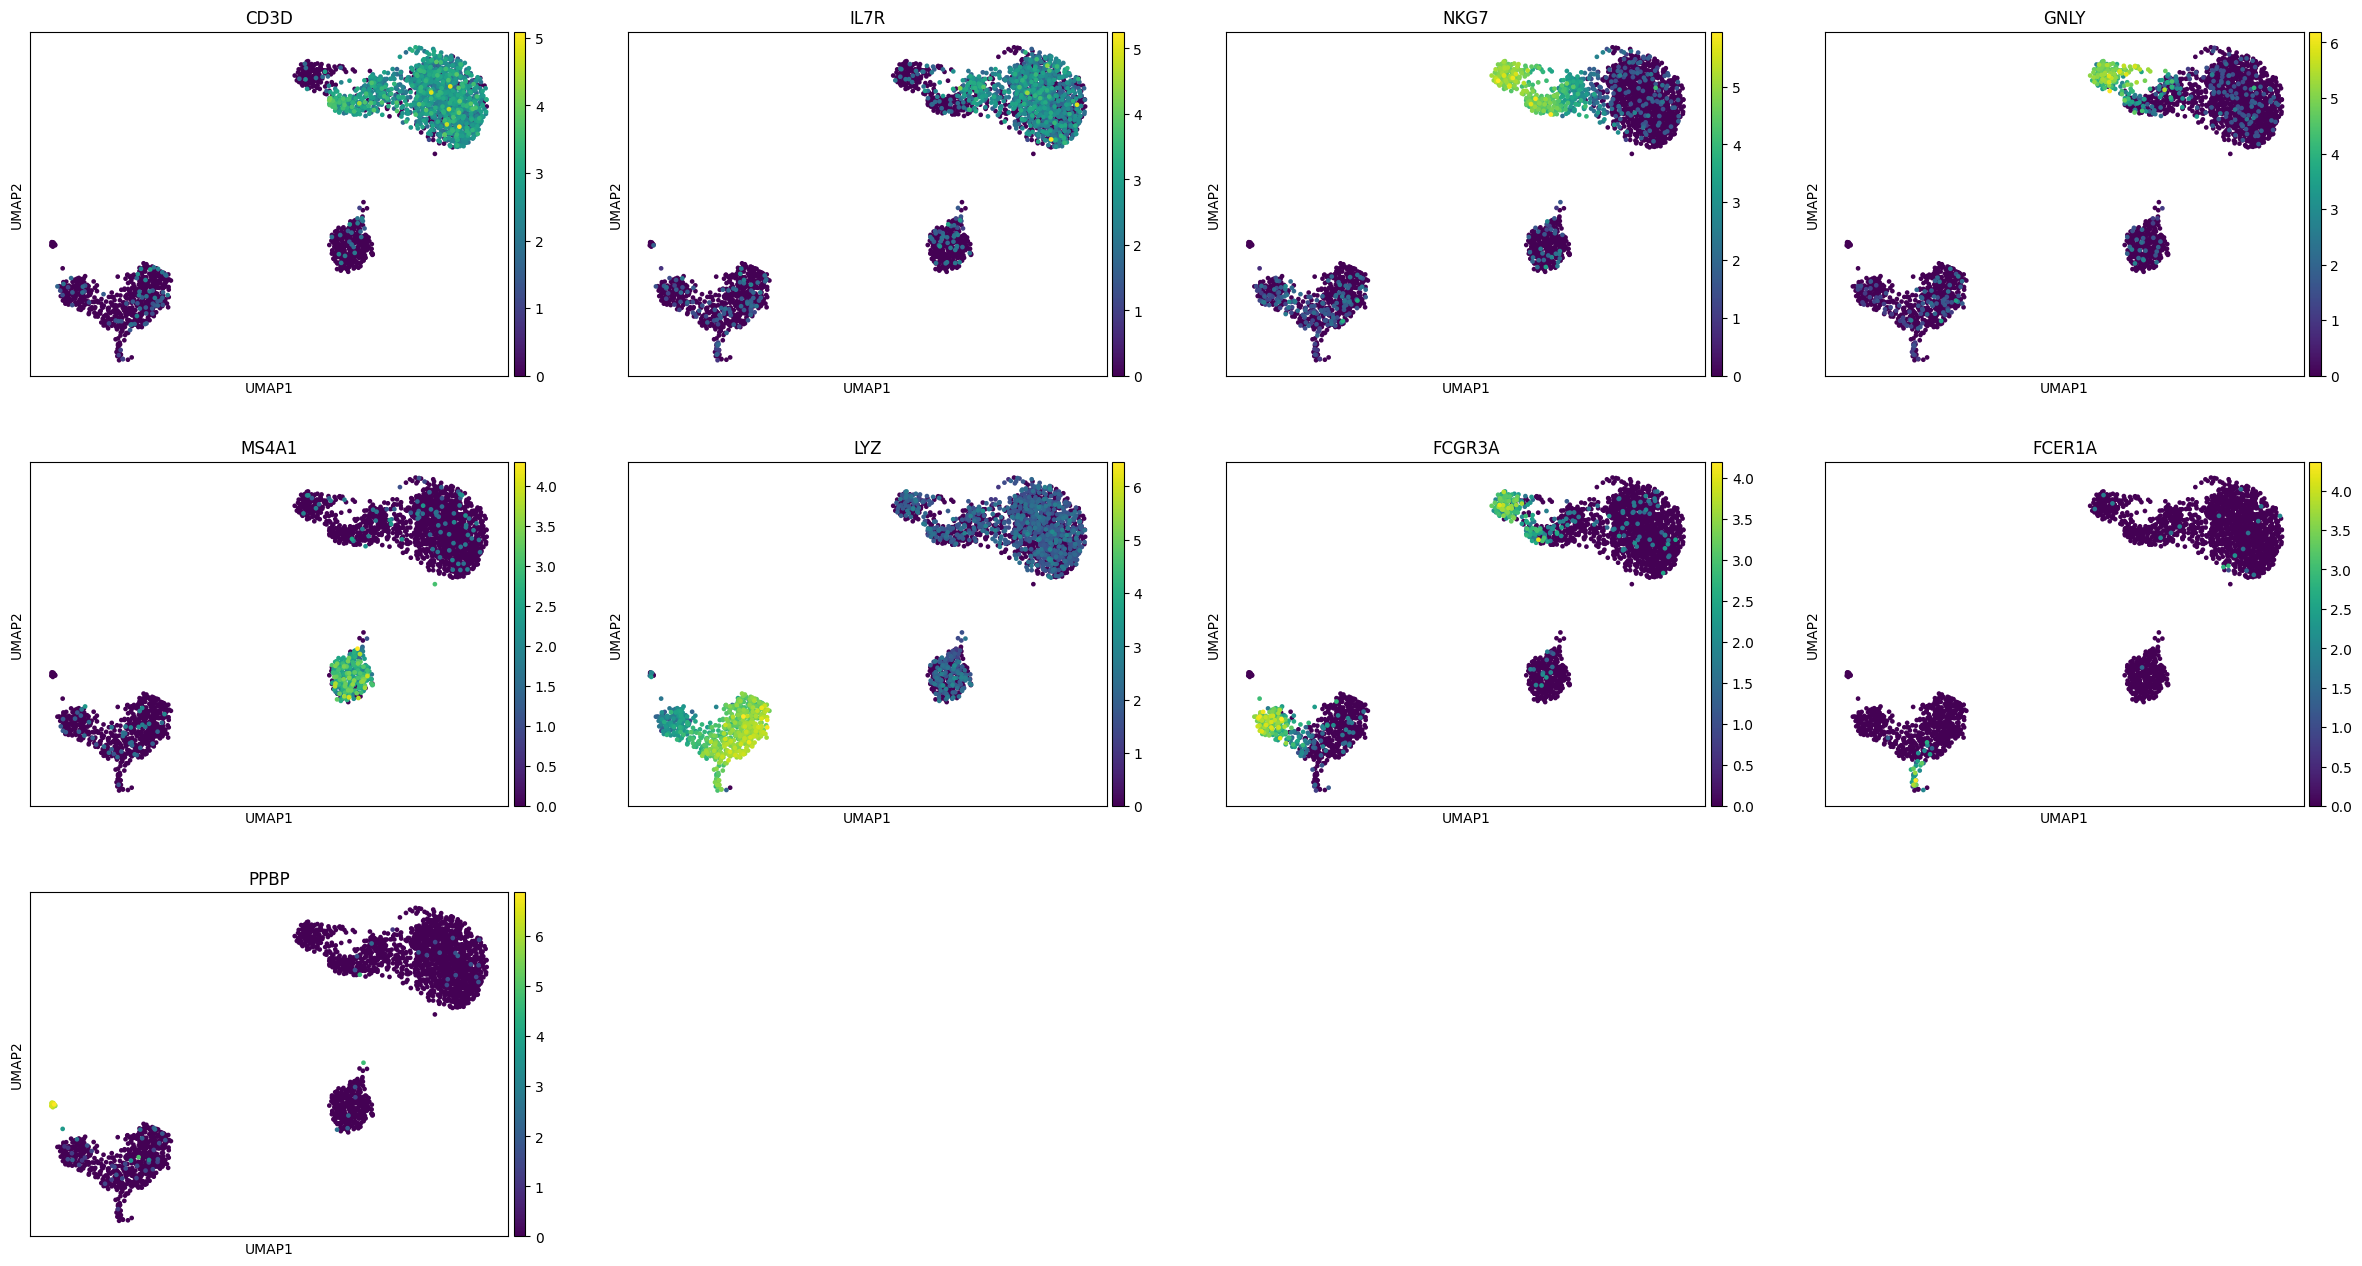

In [95]:
markers = [
    "CD3D",
    "IL7R",
    "NKG7",
    "GNLY",
    "MS4A1",
    "LYZ",
    "FCGR3A",
    "FCER1A",
    "PPBP"
]

sc.pl.umap(
    adata,
    color=markers
)

In [96]:
cell_type_map = {
    "0": "CD4 T",
    "1": "CD14 Monocyte",
    "2": "CD8 T",
    "3": "B cell",
    "4": "NK",
    "5": "FCGR3A Monocyte",
    "6": "Dendritic",
    "7": "Platelet"
}

In [97]:
adata.obs["cell_type"] = (
    adata.obs["leiden"]
    .map(cell_type_map)
    .astype("category")
)

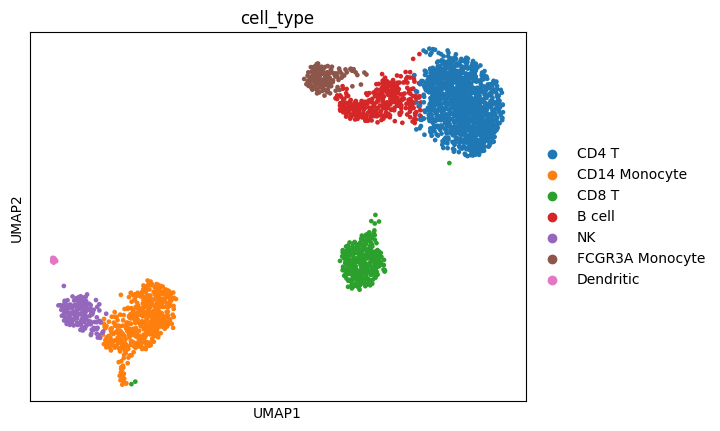

In [98]:
sc.pl.umap(
    adata,
    color="cell_type"
)

# Train/Test split 

In [104]:
adata_hgv.obs["cell_type"] = adata.obs.loc[
    adata_hgv.obs_names,
    "cell_type"
].values

In [108]:
X = adata_hgv.X
y = adata_hgv.obs["cell_type"].values

In [109]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# ML

In [118]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

In [114]:
log_reg_model = LogisticRegression(
    max_iter=2000
)

In [116]:
log_reg_model.fit(X_train, y_train)

y_pred = log_reg_model.predict(X_test)

In [117]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9772727272727273
                 precision    recall  f1-score   support

         B cell       0.92      0.91      0.92        66
  CD14 Monocyte       1.00      0.99      1.00       101
          CD4 T       0.98      0.98      0.98       225
          CD8 T       1.00      1.00      1.00        70
      Dendritic       1.00      1.00      1.00         2
FCGR3A Monocyte       0.97      0.97      0.97        30
             NK       0.97      1.00      0.99        34

       accuracy                           0.98       528
      macro avg       0.98      0.98      0.98       528
   weighted avg       0.98      0.98      0.98       528



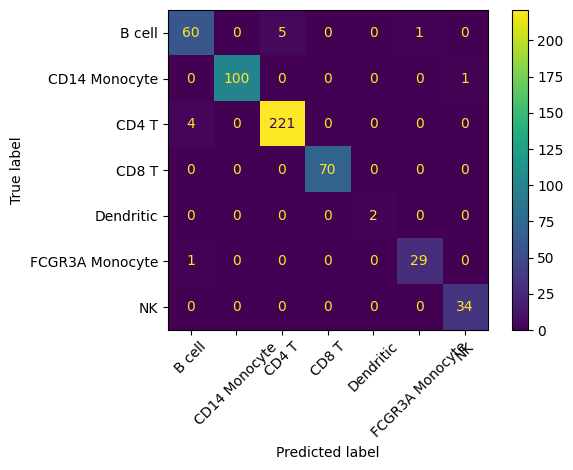

In [119]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=45
)

plt.tight_layout()
plt.show()

# Interpretation : Most Important Genes

In [123]:
genes = np.array(adata_hgv.var_names)

for i, cell_type in enumerate(log_reg_model.classes_):
    coef = log_reg_model.coef_[i]

    top_idx = np.argsort(coef)[-10:][::-1]

    print(f"\nTop genes for {cell_type}:")
    for idx in top_idx:
        print(f"{genes[idx]:15s} {coef[idx]:.3f}")


Top genes for B cell:
CCL5            0.745
NKG7            0.580
GZMK            0.349
CST7            0.293
CTSW            0.290
IL32            0.284
GZMA            0.234
LYAR            0.209
KLRG1           0.197
CD2             0.188

Top genes for CD14 Monocyte:
LYZ             0.450
LGALS2          0.405
S100A8          0.380
S100A9          0.273
GSTP1           0.269
MS4A6A          0.233
HLA-DMA         0.168
GPX1            0.168
HLA-DRA         0.155
TYROBP          0.149

Top genes for CD4 T:
MALAT1          0.282
TPT1            0.238
RPL13           0.215
B2M             0.203
RPS3A           0.190
RPS5            0.187
RPS27A          0.186
RPL21           0.184
UBE2D2          0.161
IL32            0.155

Top genes for CD8 T:
CD79A           0.346
HLA-DRA         0.338
CD79B           0.286
CD74            0.283
MS4A1           0.218
HLA-DRB1        0.209
HLA-DPB1        0.188
HLA-DQA1        0.175
HLA-DPA1        0.169
CD37            0.165

Top genes for Dendriti

In [125]:
top_genes = {}

for i, cell_type in enumerate(log_reg_model.classes_):
    coef = log_reg_model.coef_[i]
    top_idx = np.argsort(coef)[-10:][::-1]

    top_genes[cell_type] = genes[top_idx]

top_genes_df = pd.DataFrame(top_genes)

print(top_genes_df)

  B cell CD14 Monocyte   CD4 T     CD8 T  Dendritic FCGR3A Monocyte      NK
0   CCL5           LYZ  MALAT1     CD79A       PPBP            GNLY  FCGR3A
1   NKG7        LGALS2    TPT1   HLA-DRA        PF4          TYROBP    LST1
2   GZMK        S100A8   RPL13     CD79B        CLU            GZMB  FCER1G
3   CST7        S100A9     B2M      CD74      GNG11            PRF1    AIF1
4   CTSW         GSTP1   RPS3A     MS4A1       SDPR          FCER1G  IFITM3
5   IL32        MS4A6A    RPS5  HLA-DRB1       GPX1          FGFBP2   CEBPB
6   GZMA       HLA-DMA  RPS27A  HLA-DPB1        CD9          FCGR3A   CD79B
7   LYAR          GPX1   RPL21  HLA-DQA1      SPARC            NKG7   COTL1
8  KLRG1       HLA-DRA  UBE2D2  HLA-DPA1  HIST1H2AC           CD247   IFI30
9    CD2        TYROBP    IL32      CD37       CCL5            CTSW    SAT1


# A Larger Dataset

In [127]:
adata = sc.read_h5ad("data/10x-Multiome-Pbmc10k-RNA.h5ad")

In [130]:
print("Shape:", adata.shape)

print("\nCell metadata:")
print(adata.obs.head())

print("\nGene metadata:")
print(adata.var.head())

print("\nAvailable obs columns:")
print(adata.obs.columns.tolist())

print("\nCell types:")
print(adata.obs["cell_type"].value_counts())

Shape: (9631, 29095)

Cell metadata:
                       domain      protocol                   dataset  \
cells                                                                   
AAACAGCCAATCCCTT-1  scRNA-seq  10x Multiome  10x-Multiome-Pbmc10k-RNA   
AAACAGCCAATGCGCT-1  scRNA-seq  10x Multiome  10x-Multiome-Pbmc10k-RNA   
AAACAGCCACCAACCG-1  scRNA-seq  10x Multiome  10x-Multiome-Pbmc10k-RNA   
AAACAGCCAGGATAAC-1  scRNA-seq  10x Multiome  10x-Multiome-Pbmc10k-RNA   
AAACAGCCAGTTTACG-1  scRNA-seq  10x Multiome  10x-Multiome-Pbmc10k-RNA   

                       orig.ident  nCount_RNA  nFeature_RNA  percent.mt  \
cells                                                                     
AAACAGCCAATCCCTT-1  SeuratProject      3771.0        1896.0   10.527711   
AAACAGCCAATGCGCT-1  SeuratProject      6876.0        2904.0    6.457243   
AAACAGCCACCAACCG-1  SeuratProject      5415.0        2282.0    6.500462   
AAACAGCCAGGATAAC-1  SeuratProject      2759.0        1353.0    6.922798   
A

# QC

In [131]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")

In [132]:
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],
    percent_top=None,
    log1p=False,
    inplace=True
)

In [133]:
print(
    adata.obs[
        ["n_genes_by_counts", "total_counts", "pct_counts_mt"]
    ].describe()
)

       n_genes_by_counts  total_counts  pct_counts_mt
count        9631.000000   9631.000000    9631.000000
mean         1918.561728   4166.778809       9.828856
std           572.182036   1855.497925       3.291593
min           617.000000   1006.000000       0.148715
25%          1532.000000   2955.000000       7.479646
50%          1805.000000   3712.000000       9.612496
75%          2185.500000   4870.500000      11.956646
max          5424.000000  22586.000000      19.981106


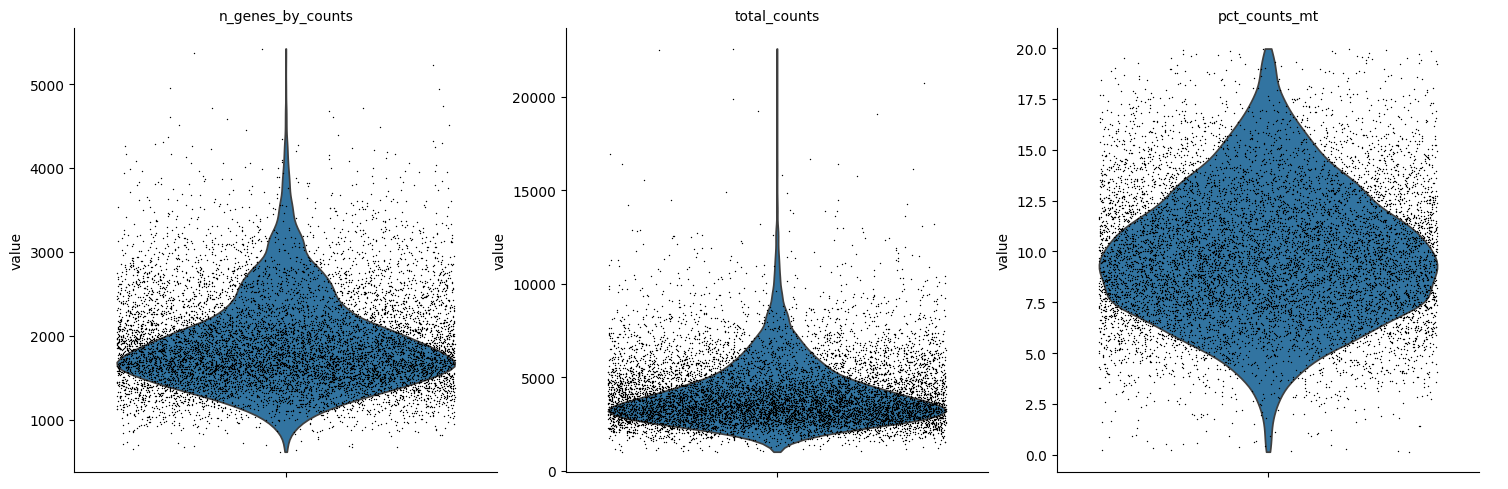

In [134]:
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True
)

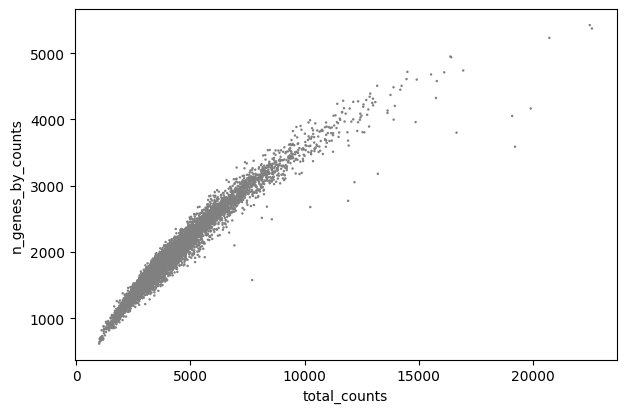

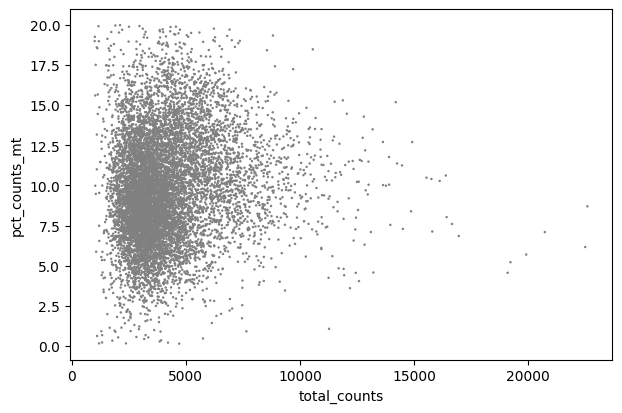

In [135]:
sc.pl.scatter(
    adata,
    x="total_counts",
    y="n_genes_by_counts"
)

sc.pl.scatter(
    adata,
    x="total_counts",
    y="pct_counts_mt"
)

In [136]:
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

In [137]:
adata = adata[
    (adata.obs["n_genes_by_counts"] < 5000) &
    (adata.obs["pct_counts_mt"] < 15)
].copy()

In [138]:
print("After QC:", adata.shape)

After QC: (8941, 25523)


# Normalization

In [139]:
adata.layers["counts"] = adata.X.copy()

In [140]:
sc.pp.normalize_total(
    adata,
    target_sum=1e4
)

# Log Transformation

In [141]:
sc.pp.log1p(adata)

# HVG

In [142]:
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor="seurat"
)

In [143]:
print(adata.var["highly_variable"].value_counts())

highly_variable
False    23523
True      2000
Name: count, dtype: int64


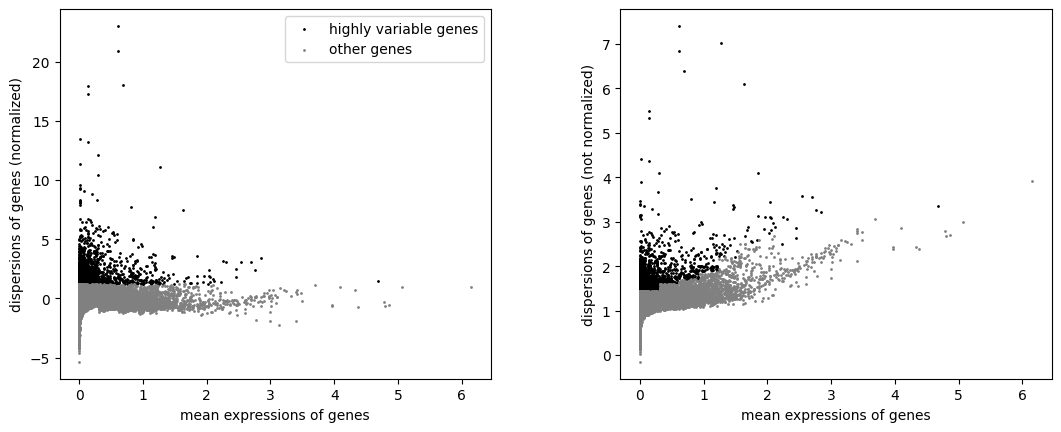

In [144]:
sc.pl.highly_variable_genes(adata)

In [145]:
adata_hvg = adata[:, adata.var["highly_variable"]].copy()

In [146]:
print(adata_hvg.shape)

(8941, 2000)


# Constructing the ML inputs

In [147]:
X = adata_hvg.X

In [148]:
y = adata_hvg.obs["cell_type"].astype(str).values

In [149]:
print(X.shape)
print(y.shape)

print(pd.Series(y).value_counts())

(8941, 2000)
(8941,)
CD14 Mono         2204
CD4 Naive         1375
CD8 Naive         1296
CD4 TCM           1095
NK                 392
CD16 Mono          369
CD8 TEM_1          316
CD8 TEM_2          310
CD4 TEM            276
Memory B           259
Intermediate B     256
Treg               152
cDC                151
gdT                138
MAIT               129
pDC                 98
Naive B             96
HSPC                17
Plasma              12
Name: count, dtype: int64


In [150]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [151]:
print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (7152, 2000)
Test: (1789, 2000)


# Log Reg

In [153]:
logreg = LogisticRegression(
    max_iter=3000
)

logreg.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",3000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [154]:
y_pred_logreg = logreg.predict(X_test)

# Evaluation

In [155]:
print(
    "Accuracy:",
    accuracy_score(y_test, y_pred_logreg)
)

Accuracy: 0.9278926774734488


In [156]:
print(
    classification_report(
        y_test,
        y_pred_logreg
    )
)

                precision    recall  f1-score   support

     CD14 Mono       0.98      1.00      0.99       441
     CD16 Mono       0.99      0.95      0.97        74
     CD4 Naive       0.91      0.93      0.92       275
       CD4 TCM       0.85      0.83      0.84       219
       CD4 TEM       0.75      0.73      0.74        55
     CD8 Naive       0.96      0.98      0.97       259
     CD8 TEM_1       0.85      0.73      0.79        63
     CD8 TEM_2       0.83      0.92      0.87        62
          HSPC       1.00      1.00      1.00         3
Intermediate B       0.98      0.92      0.95        51
          MAIT       0.96      0.92      0.94        26
      Memory B       0.98      0.98      0.98        52
            NK       0.97      0.97      0.97        79
       Naive B       0.78      0.95      0.86        19
        Plasma       1.00      0.50      0.67         2
          Treg       0.84      0.87      0.86        31
           cDC       1.00      0.90      0.95  

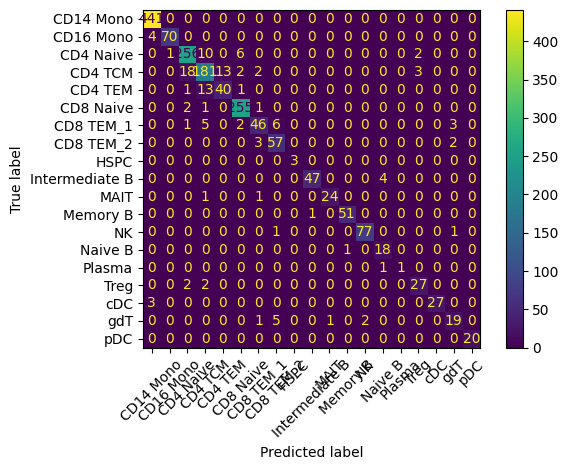

In [157]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_logreg,
    xticks_rotation=45
)

plt.tight_layout()
plt.show()

# Interpretation

In [158]:
genes = np.array(adata_hvg.var_names)

top_genes = {}

for i, cell_type in enumerate(logreg.classes_):

    coefficients = logreg.coef_[i]

    top_indices = np.argsort(coefficients)[-10:][::-1]

    top_genes[cell_type] = genes[top_indices]

    print(f"\nTop genes for {cell_type}")

    for idx in top_indices:
        print(
            f"{genes[idx]:15s}",
            f"{coefficients[idx]:.3f}"
        )


Top genes for CD14 Mono
FRMD4B          0.339
NEAT1           0.295
STX11           0.294
CSF3R           0.291
SLC8A1          0.269
CD36            0.265
ZEB2            0.263
ATF3            0.263
AOAH            0.246
MARCH1          0.244

Top genes for CD16 Mono
TCF7L2          0.405
FCGR3A          0.391
CDKN1C          0.351
IFITM3          0.337
MS4A7           0.303
FMNL2           0.300
AIF1            0.290
CFD             0.282
LST1            0.242
SETBP1          0.237

Top genes for CD4 Naive
FHIT            0.973
EDA             0.819
AK5             0.692
BACH2           0.674
ANKRD55         0.627
MAML2           0.511
IGF1R           0.465
KLHL29          0.455
AFF3            0.444
TSHZ2           0.439

Top genes for CD4 TCM
IFNG-AS1        0.709
INPP4B          0.690
ITGB1           0.553
MKI67           0.532
MYO16           0.518
SGPP2           0.514
PYHIN1          0.513
SEMA5A          0.476
EPHA4           0.443
TAFA1           0.437

Top genes for CD4 TEM

In [159]:
top_genes_df = pd.DataFrame(top_genes)

top_genes_df

,CD14 Mono,CD16 Mono,CD4 Naive,CD4 TCM,CD4 TEM,CD8 Naive,CD8 TEM_1,CD8 TEM_2,HSPC,Intermediate B,MAIT,Memory B,NK,Naive B,Plasma,Treg,cDC,gdT,pDC
0,FRMD4B,TCF7L2,FHIT,IFNG-AS1,ITGB1,NELL2,CCL5,GZMH,SOX4,IGHM,SLC4A10,TCL1A,TXK,PDE4D,JCHAIN,IKZF2,NEGR1,TRDC,TCF4
1,NEAT1,FCGR3A,EDA,INPP4B,PTPN13,CD8B,GZMK,CD8A,ZNF385D,SOX5,ADAM12,IL4R,GNLY,EBF1,IGHA1,IL2RA,CCSER1,GNLY,AC023590.1
2,STX11,CDKN1C,AK5,ITGB1,AUTS2,CD8A,IKZF2,NKG7,CDK6,GPM6A,PHACTR2,IGHD,ZBTB16,IFNG-AS1,TXNDC5,RTKN2,ALCAM,KLRC2,ZFAT
3,CSF3R,IFITM3,BACH2,MKI67,TMEM156,BACH2,IFNG-AS1,CCL5,NKAIN2,CSGALNACT1,NKG7,IGHM,FCER1G,COCH,MZB1,AL136456.1,HDAC9,IKZF2,LINC01478
4,SLC8A1,MS4A7,ANKRD55,MYO16,GREM2,PTPRK,NELL2,MSC-AS1,ERG,RALGPS2,PLCB1,COL19A1,KLRF1,VPREB3,IGKC,AC093865.1,CST3,TRGC1,IRF8
5,CD36,FMNL2,MAML2,SGPP2,PDE4D,KLRK1,KLRK1,TRGC2,AUTS2,OSBPL10,KLRB1,MEF2C,NCAM1,CR1,IGLC1,RBMS3,HLA-DQB1,ZEB2,PLD4
6,ZEB2,AIF1,IGF1R,PYHIN1,FRY,SNED1,CD8B,GNLY,MEIS1,ARHGAP24,LINC00299,AFF3,BNC2,SSPN,IGLC2,LINC02694,EMP1,SETBP1,EPHB1
7,ATF3,CFD,KLHL29,SEMA5A,KLRB1,LY86-AS1,EPHA4,ITGB1,ST8SIA6,MS4A1,ZBTB16,FCER2,LINC00299,BANK1,IGHG2,PELI1,HLA-DQA1,LINC00944,LINC01374
8,AOAH,LST1,AFF3,EPHA4,LINC01644,LINC02446,TPRG1,MIAT,MED12L,CD79A,AL136456.1,FCRL1,MCTP2,FAM30A,ITM2C,CLYBL,HLA-DPA1,GZMH,UGCG
9,MARCH1,SETBP1,TSHZ2,TAFA1,COLQ,CA6,AOAH,FGFBP2,ATP8B4,BANK1,IFNG-AS1,BACH2,PRF1,KYNU,IGHG1,ARID5B,AFF3,KLRC3,PLXNA4


# RF

In [162]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

In [160]:
X_train_dense = (
    X_train.toarray()
    if hasattr(X_train, "toarray")
    else X_train
)

X_test_dense = (
    X_test.toarray()
    if hasattr(X_test, "toarray")
    else X_test
)

In [163]:
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf.fit(
    X_train_dense,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [164]:
y_pred_rf = rf.predict(X_test_dense)

In [165]:
print(
    "Random Forest accuracy:",
    accuracy_score(y_test, y_pred_rf)
)

print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

Random Forest accuracy: 0.8915595304639463
                precision    recall  f1-score   support

     CD14 Mono       0.97      1.00      0.98       441
     CD16 Mono       1.00      0.91      0.95        74
     CD4 Naive       0.88      0.95      0.91       275
       CD4 TCM       0.73      0.87      0.79       219
       CD4 TEM       0.94      0.31      0.47        55
     CD8 Naive       0.94      0.98      0.96       259
     CD8 TEM_1       0.85      0.65      0.74        63
     CD8 TEM_2       0.70      1.00      0.82        62
          HSPC       1.00      0.33      0.50         3
Intermediate B       0.86      0.98      0.92        51
          MAIT       1.00      0.69      0.82        26
      Memory B       0.94      0.96      0.95        52
            NK       0.90      0.97      0.93        79
       Naive B       1.00      0.58      0.73        19
        Plasma       1.00      0.50      0.67         2
          Treg       1.00      0.32      0.49        31
    

# MLP

In [166]:
mlp = MLPClassifier(
    hidden_layer_sizes=(256, 128),
    activation="relu",
    max_iter=300,
    random_state=42,
    early_stopping=True
)

mlp.fit(
    X_train_dense,
    y_train
)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(256, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",300
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically setaside ``validation_fraction`` of training data as validation andterminate training when validation score is not improving by at least``tol`` for ``n_iter_no_change`` consecutive epochs. The split isstratified, except in a multilabel setting.If early stopping is False, then the training stops when the trainingloss does not improve by more than ``tol`` for ``n_iter_no_change``consecutive passes over the training set.Only effective when solver='sgd' or 'adam'.",True
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating

In [167]:
y_pred_mlp = mlp.predict(X_test_dense)

In [168]:
print(
    "MLP accuracy:",
    accuracy_score(y_test, y_pred_mlp)
)

print(
    classification_report(
        y_test,
        y_pred_mlp
    )
)

MLP accuracy: 0.9362772498602572
                precision    recall  f1-score   support

     CD14 Mono       0.99      1.00      0.99       441
     CD16 Mono       0.96      0.97      0.97        74
     CD4 Naive       0.92      0.95      0.93       275
       CD4 TCM       0.87      0.88      0.88       219
       CD4 TEM       0.87      0.73      0.79        55
     CD8 Naive       0.96      0.98      0.97       259
     CD8 TEM_1       0.90      0.73      0.81        63
     CD8 TEM_2       0.82      0.98      0.90        62
          HSPC       1.00      1.00      1.00         3
Intermediate B       0.87      0.94      0.91        51
          MAIT       1.00      0.88      0.94        26
      Memory B       1.00      0.94      0.97        52
            NK       0.96      1.00      0.98        79
       Naive B       0.79      0.79      0.79        19
        Plasma       1.00      0.50      0.67         2
          Treg       0.93      0.84      0.88        31
           cDC

# Comparaison

In [170]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "MLP"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_logreg),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_mlp)
    ]
})

results

,Model,Accuracy
0,Logistic Regression,0.927893
1,Random Forest,0.891560
2,MLP,0.936277


In [171]:
results.sort_values(
    "Accuracy",
    ascending=False
)

,Model,Accuracy
2,MLP,0.936277
0,Logistic Regression,0.927893
1,Random Forest,0.891560


# Prediction Function

In [173]:
def predict_cell_type(cell_id, model, adata_hvg):
    """
    Predict the cell type of one cell.

    Parameters
    ----------
    cell_id : str
        Cell barcode / cell name, e.g. "TTTCTACTGAGGCA-1"

    model :
        A trained sklearn classifier:
        LogisticRegression, RandomForestClassifier, MLPClassifier, etc.

    adata_hvg : AnnData
        AnnData object containing the same genes/features used to train the model.

    Returns
    -------
    str
        Predicted cell type.
    """

    if cell_id not in adata_hvg.obs_names:
        raise ValueError(f"Cell {cell_id} not found in adata_hvg.")

    # Extract one cell: shape (1, n_genes)
    X_cell = adata_hvg[cell_id, :].X

    # RF and MLP were trained on dense arrays in our pipeline
    if model.__class__.__name__ in [
        "RandomForestClassifier",
        "MLPClassifier"
    ]:
        if hasattr(X_cell, "toarray"):
            X_cell = X_cell.toarray()

    prediction = model.predict(X_cell)[0]

    return prediction

In [174]:
cell = adata_hvg.obs_names[0]

prediction = predict_cell_type(
    cell,
    logreg,
    adata_hvg
)

print("Cell:", cell)
print("Predicted type:", prediction)

Cell: AAACAGCCAATCCCTT-1
Predicted type: CD4 TCM


In [175]:
predict_cell_type(
    cell,
    rf,
    adata_hvg
)

'CD4 TCM'

In [176]:
predict_cell_type(
    cell,
    mlp,
    adata_hvg
)

np.str_('CD4 TCM')

# Prediction Probability

In [177]:
def predict_cell_type_with_proba(cell_id, model, adata_hvg):
    X_cell = adata_hvg[cell_id, :].X

    if model.__class__.__name__ in [
        "RandomForestClassifier",
        "MLPClassifier"
    ]:
        if hasattr(X_cell, "toarray"):
            X_cell = X_cell.toarray()

    prediction = model.predict(X_cell)[0]

    probabilities = model.predict_proba(X_cell)[0]

    proba_dict = dict(
        zip(model.classes_, probabilities)
    )

    return prediction, proba_dict

In [178]:
prediction, probabilities = predict_cell_type_with_proba(
    cell,
    logreg,
    adata_hvg
)

print("Prediction:", prediction)

for cell_type, prob in sorted(
    probabilities.items(),
    key=lambda x: x[1],
    reverse=True
):
    print(cell_type, round(prob, 3))

Prediction: CD4 TCM
CD4 TCM 0.985
CD4 TEM 0.009
gdT 0.003
CD8 TEM_1 0.001
Treg 0.0
HSPC 0.0
CD8 TEM_2 0.0
CD8 Naive 0.0
MAIT 0.0
Intermediate B 0.0
Plasma 0.0
Naive B 0.0
pDC 0.0
NK 0.0
cDC 0.0
CD4 Naive 0.0
CD16 Mono 0.0
Memory B 0.0
CD14 Mono 0.0
